**Setup & imports**

In [ ]:
!pip install scikit-learn==1.4.2 timm -q

import os
import random
import numpy as np
import pandas as pd

from sklearn.model_selection import GroupShuffleSplit, GroupKFold
from sklearn.metrics import (
    confusion_matrix, f1_score, precision_score, recall_score, roc_curve, auc
)
from sklearn.preprocessing import label_binarize

import torch
import torch.nn as nn
from torch.utils.data import Dataset, DataLoader
from torch.utils.data.sampler import WeightedRandomSampler
from torchvision import transforms, models
from PIL import Image

import matplotlib.pyplot as plt
import seaborn as sns

# Reproducibility
SEED = 42
random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)
torch.cuda.manual_seed_all(SEED)

DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")
DEVICE


   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 12.2/12.2 MB 54.2 MB/s eta 0:00:00
ERROR: pip's dependency resolver does not currently take into account all the packages that are installed. This behaviour is the source of the following dependency conflicts.
umap-learn 0.5.9.post2 requires scikit-learn>=1.6, but you have scikit-learn 1.4.2 which is incompatible.


device(type='cuda')

Paths & global config

In [ ]:
from google.colab import drive
drive.mount('/content/drive')

DATA_ROOT = "/content/drive/MyDrive/AIMLGroup18/AnnotatedDataSet"

# Binary labels: Benign vs Suspicious+Malignant
BINARY_LABEL_MAP = {
    "Benign": 0,
    "Suspicious": 1,
    "Malignant": 1,
}
CLASS_NAMES = ["Benign", "Suspicious/Malignant"]
NUM_CLASSES = 2

RESULTS_DIR = "/content/drive/MyDrive/AIMLGroup18/Ekyaalo_Binary_Classifier/MobileNet_V3"
os.makedirs(RESULTS_DIR, exist_ok=True)
RESULTS_DIR


Mounted at /content/drive


'/content/drive/MyDrive/AIMLGroup18/Ekyaalo_Binary_Classifier/MobileNet_V3'

Build metadata (and slide IDs for group splitting)

In [ ]:
rows = []
for cls_name, bin_label in BINARY_LABEL_MAP.items():
    cls_dir = os.path.join(DATA_ROOT, cls_name)
    if not os.path.isdir(cls_dir):
        print(f"Warning: directory not found: {cls_dir}")
        continue

    for fname in os.listdir(cls_dir):
        if not fname.lower().endswith(('.png', '.jpg', '.jpeg', '.tif', '.tiff', '.bmp')):
            continue
        fpath = os.path.join(cls_dir, fname)

        # Extract slide_id from filename:
        # pattern examples:
        #  "2025-04-16T21-36-24-411Z-C1432-23-1.tif_lux_..."
        #  "2025-04-16T21-36-24-948Z-FNAC214-21-1.tif_lux_..."
        # We'll take the substring between "Z-" and ".tif"
        base = fname
        slide_id = "UNKNOWN"
        if "Z-" in base and ".tif" in base:
            try:
                slide_id = base.split("Z-")[1].split(".tif")[0]
            except Exception:
                slide_id = base  # fallback
        else:
            slide_id = base  # fallback if pattern different

        rows.append({
            "filepath": fpath,
            "fname": fname,
            "class_name": cls_name,
            "label": bin_label,
            "slide_id": slide_id,
        })

df = pd.DataFrame(rows)
print("Total images:", len(df))
print(df["label"].value_counts().rename(index={0:"Benign",1:"Susp/Malig"}))
df.head()


Total images: 817
label
Susp/Malig    571
Benign        246
Name: count, dtype: int64


,filepath,fname,class_name,label,slide_id
0,/content/drive/MyDrive/AIMLGroup18/AnnotatedDa...,2025-04-16T21-36-52-729Z-C1131-23-2.tif_lux_36...,Benign,0,C1131-23-2
1,/content/drive/MyDrive/AIMLGroup18/AnnotatedDa...,2025-04-16T21-36-51-706Z-C1432-23-1.tif_lux_48...,Benign,0,C1432-23-1
2,/content/drive/MyDrive/AIMLGroup18/AnnotatedDa...,2025-04-16T21-37-00-823Z-C1131-23-2.tif_lux_29...,Benign,0,C1131-23-2
3,/content/drive/MyDrive/AIMLGroup18/AnnotatedDa...,2025-04-16T21-36-58-977Z-C1265-23-1.tif_lux_20...,Benign,0,C1265-23-1
4,/content/drive/MyDrive/AIMLGroup18/AnnotatedDa...,2025-04-16T21-37-00-540Z-C1432-23-1.tif_lux_14...,Benign,0,C1432-23-1


Train/val/test split with slide-level separation

In [ ]:
# 1) Make a hold-out TEST set at slide level
gss = GroupShuffleSplit(n_splits=1, test_size=0.15, random_state=SEED)
trainval_idx, test_idx = next(gss.split(df, df["label"], groups=df["slide_id"]))

df_trainval = df.iloc[trainval_idx].reset_index(drop=True)
df_test     = df.iloc[test_idx].reset_index(drop=True)

print("Train+Val size:", len(df_trainval))
print("Test size:", len(df_test))

print("\nTrain+Val label counts:")
print(df_trainval["label"].value_counts().rename(index={0:"Benign",1:"Susp/Malig"}))
print("\nTest label counts:")
print(df_test["label"].value_counts().rename(index={0:"Benign",1:"Susp/Malig"}))

# 2) Prepare GroupKFold (5 folds) on the train+val portion
groups_trainval = df_trainval["slide_id"].values
gkf = GroupKFold(n_splits=5)
fold_splits = list(gkf.split(df_trainval, df_trainval["label"], groups=groups_trainval))

len(fold_splits)


Train+Val size: 605
Test size: 212

Train+Val label counts:
label
Susp/Malig    441
Benign        164
Name: count, dtype: int64

Test label counts:
label
Susp/Malig    130
Benign         82
Name: count, dtype: int64


5

**Dataset class & (optional) dataset normalization**

First define a helper to compute dataset mean/std once (you can run it and then hard-code values if you want faster future runs).

In [ ]:
class FNACBinaryDataset(Dataset):
    def __init__(self, df_subset, transform=None):
        self.df = df_subset.reset_index(drop=True)
        self.transform = transform

    def __len__(self):
        return len(self.df)

    def __getitem__(self, idx):
        row = self.df.iloc[idx]
        img = Image.open(row["filepath"]).convert("RGB")
        label = int(row["label"])
        if self.transform:
            img = self.transform(img)
        return img, label


def compute_mean_std(df_subset, max_samples=2000):
    """
    Approximate per-channel mean/std over a subset of images.
    """
    dataset = FNACBinaryDataset(
    df_subset.sample(n=min(len(df_subset), max_samples), random_state=SEED),
    transform=transforms.Compose([
        transforms.Resize((224, 224)),
        transforms.ToTensor(),
        ])
    )

    loader = DataLoader(dataset, batch_size=32, shuffle=False, num_workers=2)

    n_pixels = 0
    channel_sum = torch.zeros(3)
    channel_sq_sum = torch.zeros(3)

    for imgs, _ in loader:
        # imgs: (B, C, H, W)
        b, c, h, w = imgs.shape
        pixels = b * h * w
        n_pixels += pixels
        channel_sum += imgs.sum(dim=[0, 2, 3])
        channel_sq_sum += (imgs ** 2).sum(dim=[0, 2, 3])

    mean = channel_sum / n_pixels
    std = (channel_sq_sum / n_pixels - mean ** 2).sqrt()
    return mean.tolist(), std.tolist()


# ---- OPTION A: Use ImageNet normalization (good if using ImageNet-pretrained backbone) ----
IMAGENET_MEAN = [0.485, 0.456, 0.406]
IMAGENET_STD  = [0.229, 0.224, 0.225]

# ---- OPTION B: Compute dataset-specific mean/std (run once; then hard-code result) ----
USE_DATASET_STATS = True  # set True to compute mean/std

if USE_DATASET_STATS:
    train_mean, train_std = compute_mean_std(df_trainval)
    print("Dataset mean:", train_mean)
    print("Dataset std:", train_std)
else:
    train_mean, train_std = IMAGENET_MEAN, IMAGENET_STD
    print("Using ImageNet mean/std:", train_mean, train_std)


Dataset mean: [0.589268147945404, 0.5228391289710999, 0.7881168127059937]
Dataset std: [0.27295586466789246, 0.28901806473731995, 0.1528770625591278]


**Transforms**

(You can expand augmentations later; this is conservative.)

In [ ]:
train_transform = transforms.Compose([
    transforms.Resize((224, 224)),
    transforms.RandomHorizontalFlip(),
    transforms.RandomVerticalFlip(),
    transforms.RandomRotation(10),
    transforms.ToTensor(),
    transforms.Normalize(mean=train_mean, std=train_std),
])

val_test_transform = transforms.Compose([
    transforms.Resize((224, 224)),
    transforms.ToTensor(),
    transforms.Normalize(mean=train_mean, std=train_std),
])


In [ ]:
import timm

USE_CYTOFM = False  # <<< flip to True AFTER you fill the CytoFM code block below


def create_model(num_classes=NUM_CLASSES):
    if USE_CYTOFM:
        print(f"Loading CytoFM model: {CYTOFM_MODEL_NAME}")

        # Create the backbone from timm (no pretrained head)
        model = timm.create_model(
            CYTOFM_MODEL_NAME,
            pretrained=False,
            num_classes=num_classes   # We replace the classifier
        )

        # Load checkpoint
        ckpt = torch.load(CYTOFM_CKPT_PATH, map_location="cpu")

        # Check for state_dict key
        if "state_dict" in ckpt:
            state = ckpt["state_dict"]
        else:
            state = ckpt

        # Remove classifier weights if mismatched
        state = {k: v for k, v in state.items() if "head" not in k}

        missing, unexpected = model.load_state_dict(state, strict=False)
        print("Missing keys:", missing)
        print("Unexpected keys:", unexpected)

        return model.to(DEVICE)

    else:
      print("Loading MobileNetV3-Small backbone...")
      model = timm.create_model(
          "mobilenetv3_small_100",
          pretrained=True,
          num_classes=num_classes
      )
      return model.to(DEVICE)



model = create_model().to(DEVICE)
model

Loading MobileNetV3-Small backbone...


/usr/local/lib/python3.12/dist-packages/huggingface_hub/utils/_auth.py:94: UserWarning: 
The secret `HF_TOKEN` does not exist in your Colab secrets.
To authenticate with the Hugging Face Hub, create a token in your settings tab (https://huggingface.co/settings/tokens), set it as secret in your Google Colab and restart your session.
You will be able to reuse this secret in all of your notebooks.
Please note that authentication is recommended but still optional to access public models or datasets.
  warnings.warn(


model.safetensors:   0%|          | 0.00/10.2M [00:00<?, ?B/s]

MobileNetV3(
  (conv_stem): Conv2d(3, 16, kernel_size=(3, 3), stride=(2, 2), padding=(1, 1), bias=False)
  (bn1): BatchNormAct2d(
    16, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True
    (drop): Identity()
    (act): Hardswish()
  )
  (blocks): Sequential(
    (0): Sequential(
      (0): DepthwiseSeparableConv(
        (conv_dw): Conv2d(16, 16, kernel_size=(3, 3), stride=(2, 2), padding=(1, 1), groups=16, bias=False)
        (bn1): BatchNormAct2d(
          16, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True
          (drop): Identity()
          (act): ReLU(inplace=True)
        )
        (aa): Identity()
        (se): SqueezeExcite(
          (conv_reduce): Conv2d(16, 8, kernel_size=(1, 1), stride=(1, 1))
          (act1): ReLU(inplace=True)
          (conv_expand): Conv2d(8, 16, kernel_size=(1, 1), stride=(1, 1))
          (gate): Hardsigmoid()
        )
        (conv_pw): Conv2d(16, 16, kernel_size=(1, 1), stride=(1, 1), bias=False)
        (bn2): B

**Metrics utilities (binary but reusing multiclass code)**

In [ ]:
def compute_metrics(all_labels, all_preds, all_probs, num_classes=NUM_CLASSES):
    f1 = f1_score(all_labels, all_preds, average='weighted')
    precision = precision_score(all_labels, all_preds, average='weighted')
    recall = recall_score(all_labels, all_preds)

    # For AUC, we need to handle the binary case specifically as roc_curve expects
    # scores for the positive class.
    if num_classes == 2:
        # all_probs is (N, 2), we need scores for the positive class (index 1)
        fpr, tpr, _ = roc_curve(all_labels, all_probs[:, 1])
        roc_auc = auc(fpr, tpr)
        # Store as a dictionary for consistency, though only one value for binary
        roc_auc_dict = {"macro": roc_auc, "micro": roc_auc} # Macro/micro are same for binary

    else:
        # Binarize labels for macro/micro AUC for multiclass (not used here)
        binarized_labels = label_binarize(all_labels, classes=range(num_classes))
        roc_auc_dict = {}
        for i in range(num_classes):
            fpr, tpr, _ = roc_curve(binarized_labels[:, i], all_probs[:, i])
            roc_auc_dict[CLASS_NAMES[i]] = auc(fpr, tpr) # Use class names if available

        # Calculate macro and micro average AUC for multiclass
        fpr_macro, tpr_macro, _ = roc_curve(binarized_labels.ravel(), all_probs.ravel())
        roc_auc_dict["macro"] = auc(fpr_macro, tpr_macro)

        fpr_micro, tpr_micro, _ = roc_curve(binarized_labels.ravel(), all_probs.ravel())
        roc_auc_dict["micro"] = auc(fpr_micro, tpr_micro)


    return {
        "f1": f1,
        "precision": precision,
        "recall": recall,
        "roc_auc": roc_auc_dict # Return the dictionary
    }

# **Train the Model**
Add your training transform + val/test transform

In [ ]:
# --- Transforms ---
train_transform = transforms.Compose([
    transforms.Resize((224, 224)),
    transforms.RandomHorizontalFlip(),
    transforms.RandomVerticalFlip(),
    transforms.ColorJitter(brightness=0.15, contrast=0.15, saturation=0.15),
    transforms.ToTensor(),
    transforms.Normalize(mean=train_mean, std=train_std)
])

val_transform = transforms.Compose([
    transforms.Resize((224, 224)),
    transforms.ToTensor(),
    transforms.Normalize(mean=train_mean, std=train_std)
])


Generating Augmentation Examples…


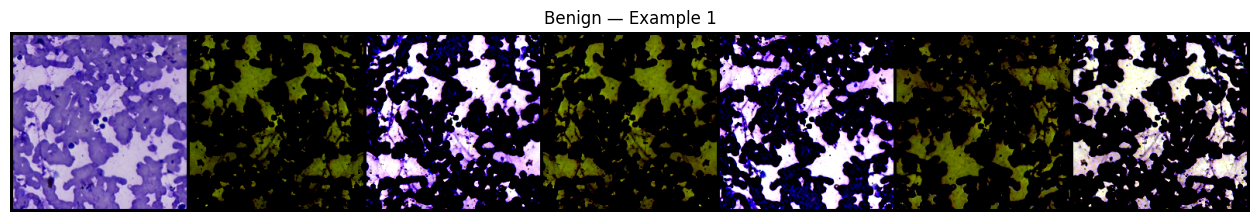

Saved: /content/drive/MyDrive/AIMLGroup18/Ekyaalo_Binary_Classifier/MobileNet_V3/augmentation_examples/Benign_example_1.png


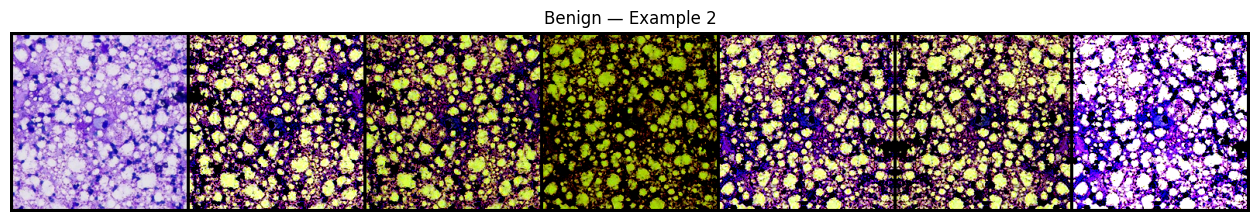

Saved: /content/drive/MyDrive/AIMLGroup18/Ekyaalo_Binary_Classifier/MobileNet_V3/augmentation_examples/Benign_example_2.png


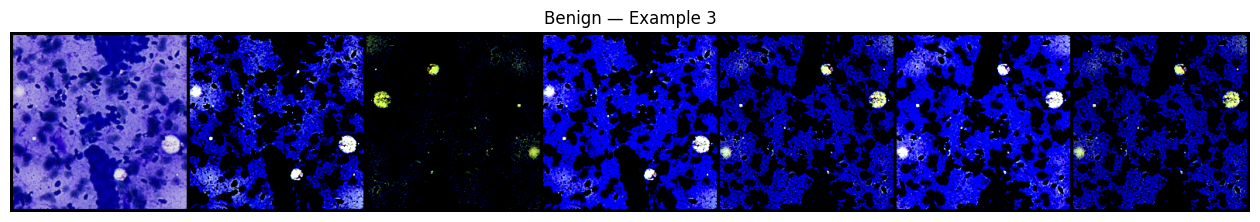

Saved: /content/drive/MyDrive/AIMLGroup18/Ekyaalo_Binary_Classifier/MobileNet_V3/augmentation_examples/Benign_example_3.png


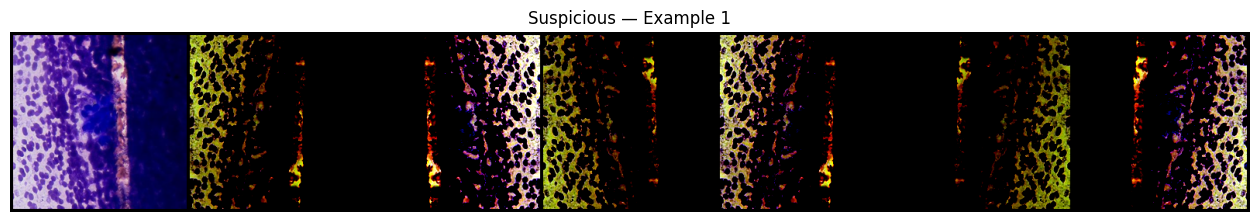

Saved: /content/drive/MyDrive/AIMLGroup18/Ekyaalo_Binary_Classifier/MobileNet_V3/augmentation_examples/Suspicious_example_1.png


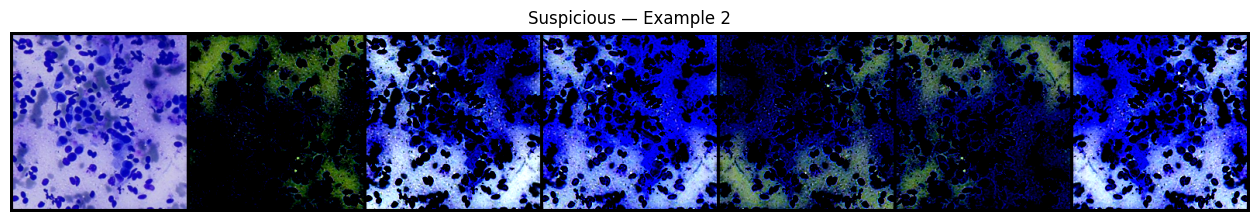

Saved: /content/drive/MyDrive/AIMLGroup18/Ekyaalo_Binary_Classifier/MobileNet_V3/augmentation_examples/Suspicious_example_2.png


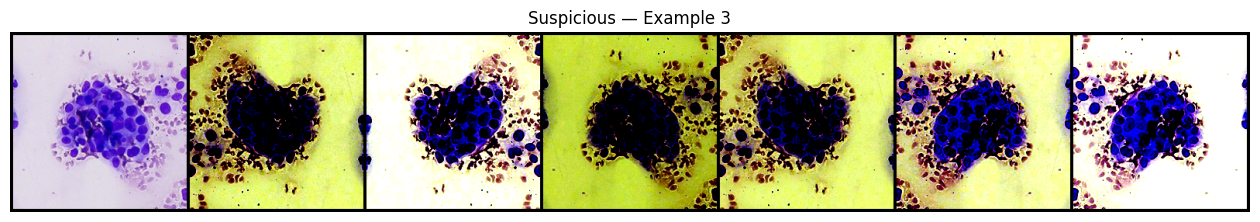

Saved: /content/drive/MyDrive/AIMLGroup18/Ekyaalo_Binary_Classifier/MobileNet_V3/augmentation_examples/Suspicious_example_3.png


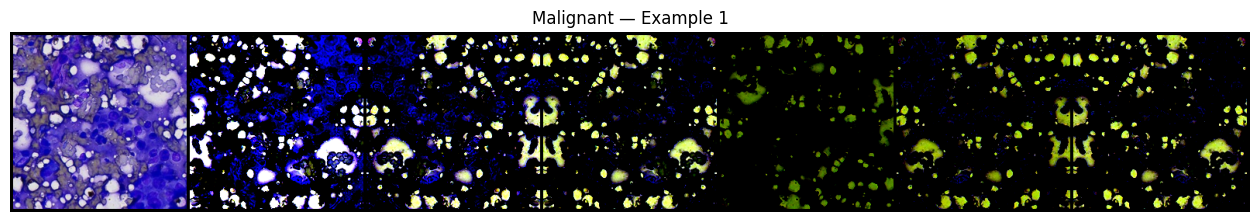

Saved: /content/drive/MyDrive/AIMLGroup18/Ekyaalo_Binary_Classifier/MobileNet_V3/augmentation_examples/Malignant_example_1.png


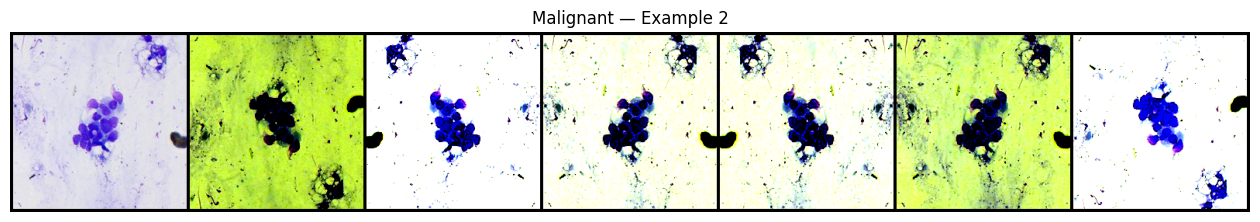

Saved: /content/drive/MyDrive/AIMLGroup18/Ekyaalo_Binary_Classifier/MobileNet_V3/augmentation_examples/Malignant_example_2.png


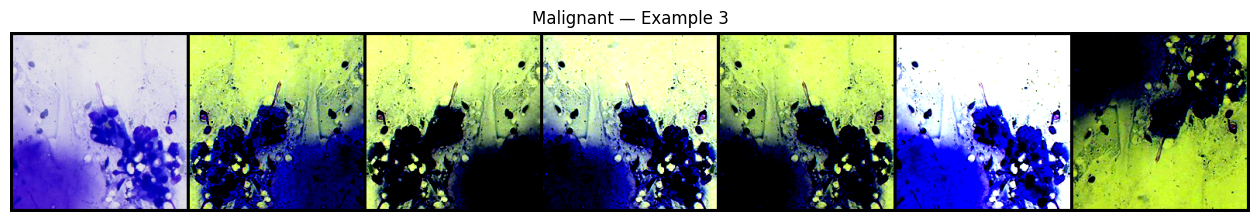

Saved: /content/drive/MyDrive/AIMLGroup18/Ekyaalo_Binary_Classifier/MobileNet_V3/augmentation_examples/Malignant_example_3.png

Augmentation examples saved in: /content/drive/MyDrive/AIMLGroup18/Ekyaalo_Binary_Classifier/MobileNet_V3/augmentation_examples


In [ ]:
import random
from torchvision.utils import save_image, make_grid

AUG_EXAMPLE_DIR = os.path.join(RESULTS_DIR, "augmentation_examples")
os.makedirs(AUG_EXAMPLE_DIR, exist_ok=True)

def show_and_save_augmentations(df, transform, class_name, n_examples=3, n_augs=6):
    """
    Generates before/after augmentation visualizations.
    - df: dataframe containing filepaths + labels
    - transform: your train_transform
    - class_name: Benign, Suspicious, Malignant
    - n_examples: number of source images to sample
    - n_augs: number of augmentation samples per image
    """
    subset = df[df["class_name"] == class_name]
    subset = subset.sample(n=min(n_examples, len(subset)), random_state=SEED)

    # Get the resize transformation from the provided transform
    resize_transform = transforms.Resize((224, 224))


    for idx, row in enumerate(subset.itertuples()):
        img_path = row.filepath

        # Load original
        orig = Image.open(img_path).convert("RGB")
        # Apply the same resize transform as the augmentation pipeline
        orig_tensor = transforms.ToTensor()(resize_transform(orig))


        # Apply augmentations n times
        aug_tensors = []
        for _ in range(n_augs):
            aug_tensors.append(transform(orig))

        # Combine into one grid (1 original + augmentations)
        grid = make_grid([orig_tensor] + aug_tensors, nrow=n_augs+1, padding=4)

        # Save path
        save_path = os.path.join(AUG_EXAMPLE_DIR, f"{class_name}_example_{idx+1}.png")
        save_image(grid, save_path)

        # Display inline
        plt.figure(figsize=(16, 3))
        plt.imshow(grid.permute(1, 2, 0))
        plt.axis("off")
        plt.title(f"{class_name} — Example {idx+1}")
        plt.show()

        print("Saved:", save_path)


# ===== RUN FOR EACH CLASS =====

print("\nGenerating Augmentation Examples…")

# The Suspicious and Malignant classes are combined into one "Suspicious/Malignant"
# class for binary classification. However, for visualization purposes,
# we can still show examples from the original "Suspicious" and "Malignant" folders
# if they exist.
show_and_save_augmentations(df, train_transform, "Benign")
if "Suspicious" in df["class_name"].unique():
    show_and_save_augmentations(df, train_transform, "Suspicious")
if "Malignant" in df["class_name"].unique():
    show_and_save_augmentations(df, train_transform, "Malignant")


print("\nAugmentation examples saved in:", AUG_EXAMPLE_DIR)

Build PyTorch datasets + dataloaders

In [ ]:
from torch.utils.data import DataLoader

BATCH_SIZE = 32

def make_loaders(df_train, df_val):
    train_set = FNACBinaryDataset(df_train, transform=train_transform)
    val_set   = FNACBinaryDataset(df_val, transform=val_transform)

    train_loader = DataLoader(train_set, batch_size=BATCH_SIZE, shuffle=True, num_workers=2)
    val_loader   = DataLoader(val_set, batch_size=BATCH_SIZE, shuffle=False, num_workers=2)

    return train_loader, val_loader


Add the training loop

In [ ]:
def train_one_epoch(model, loader, criterion, optimizer):
    model.train()
    total = 0
    correct = 0
    running_loss = 0.0

    for imgs, labels in loader:
        imgs = imgs.to(DEVICE)
        labels = labels.to(DEVICE)

        optimizer.zero_grad()
        outputs = model(imgs)
        loss = criterion(outputs, labels)
        loss.backward()
        optimizer.step()

        _, preds = outputs.max(1)
        total += labels.size(0)
        correct += preds.eq(labels).sum().item()
        running_loss += loss.item() * labels.size(0)

    acc = correct / total
    avg_loss = running_loss / total
    return avg_loss, acc


def validate(model, loader, criterion):
    model.eval()
    total = 0
    correct = 0
    running_loss = 0.0

    all_labels = []
    all_preds = []
    all_probs = []

    with torch.no_grad():
        for imgs, labels in loader:
            imgs = imgs.to(DEVICE)
            labels = labels.to(DEVICE)

            outputs = model(imgs)
            loss = criterion(outputs, labels)

            probs = torch.softmax(outputs, dim=1)
            _, preds = outputs.max(1)

            total += labels.size(0)
            correct += preds.eq(labels).sum().item()
            running_loss += loss.item() * labels.size(0)

            all_labels.extend(labels.cpu().numpy())
            all_preds.extend(preds.cpu().numpy())
            all_probs.extend(probs.cpu().numpy())

    acc = correct / total
    avg_loss = running_loss / total

    return avg_loss, acc, np.array(all_labels), np.array(all_preds), np.array(all_probs)


Add the K-Fold Cross Validation loop

In [ ]:
from sklearn.model_selection import StratifiedKFold
from sklearn.metrics import confusion_matrix, roc_curve, auc

NUM_FOLDS = 5
RESULTS = []

skf = StratifiedKFold(n_splits=NUM_FOLDS, shuffle=True, random_state=SEED)

for fold, (train_idx, val_idx) in enumerate(skf.split(df_trainval, df_trainval["label"])):
    print(f"\n===== Fold {fold+1}/{NUM_FOLDS} =====")

    df_train = df_trainval.iloc[train_idx].reset_index(drop=True)
    df_val   = df_trainval.iloc[val_idx].reset_index(drop=True)

    # Optional: show class distribution per fold
    print("\nClass distribution (train):")
    print(df_train["label"].value_counts().to_dict())

    train_loader, val_loader = make_loaders(df_train, df_val)

    model = create_model().to(DEVICE)
    criterion = nn.CrossEntropyLoss()
    optimizer = torch.optim.Adam(model.parameters(), lr=1e-4)

    best_val = 0
    best_metrics_fold = None

    for epoch in range(1, 16):
        tr_loss, tr_acc = train_one_epoch(model, train_loader, criterion, optimizer)
        val_loss, val_acc, y_true, y_pred, y_prob = validate(model, val_loader, criterion)

        print(f"Epoch {epoch:02d} | Train Acc {tr_acc:.3f} | Val Acc {val_acc:.3f}")

        if val_acc >= best_val:
            best_val = val_acc

            # Confusion matrix
            cm = confusion_matrix(y_true, y_pred, labels=range(NUM_CLASSES))
            tn, fp, fn, tp = cm.ravel()

            # Sensitivity and specificity
            sensitivity = tp / (tp + fn) if (tp + fn) > 0 else 0.0
            specificity = tn / (tn + fp) if (tn + fp) > 0 else 0.0

            # ROC metrics
            fpr_dict, tpr_dict, roc_auc_dict = {}, {}, {}
            if NUM_CLASSES == 2:
                fpr, tpr, _ = roc_curve(y_true, y_prob[:, 1])
                fpr_dict[1] = fpr
                tpr_dict[1] = tpr
                roc_auc_dict["macro"] = auc(fpr, tpr)
                roc_auc_dict["micro"] = auc(fpr, tpr)

            # Save tile-level predictions
            val_filenames = df_val["fname"].values
            tile_rows = []
            for t, p, pr, fn in zip(y_true, y_pred, y_prob, val_filenames):
                tile_rows.append({
                    "fold": fold,
                    "filename": fn,
                    "y_true": int(t),
                    "y_pred": int(p),
                    "y_prob": float(pr[1]),
                })
            tile_df = pd.DataFrame(tile_rows)
            tile_df.to_csv(
                f"/content/drive/MyDrive/AIMLGroup18/Ekyaalo_Binary_Classifier/MobileNet_V3/tile_preds_fold_{fold}.csv",
                index=False
            )
            print(f"Saved tile predictions for fold {fold}.")

            # Save metrics for summary CSV
            best_metrics_fold = {
                "confusion_matrix": cm,
                "fpr": fpr_dict,
                "tpr": tpr_dict,
                "roc_auc": roc_auc_dict,
                "f1": f1_score(y_true, y_pred, average='weighted'),
                "precision": precision_score(y_true, y_pred, average='weighted'),
                "recall": recall_score(y_true, y_pred),
                "sensitivity": sensitivity,
                "specificity": specificity
            }

            SAVE_PATH = f"/content/drive/MyDrive/AIMLGroup18/Ekyaalo_Binary_Classifier/MobileNet_V3/Model_Weights/best_fold_{fold+1}.pth"
            torch.save(model.state_dict(), SAVE_PATH)
            print(f"Saved best model for fold {fold+1} to {SAVE_PATH}")

    RESULTS.append({
        "fold": fold,
        "accuracy": best_val,
        "f1": best_metrics_fold["f1"],
        "precision": best_metrics_fold["precision"],
        "recall": best_metrics_fold["recall"],
        "sensitivity": best_metrics_fold["sensitivity"],
        "specificity": best_metrics_fold["specificity"],
        "auc": best_metrics_fold["roc_auc"]["macro"],
        "confusion_matrix": best_metrics_fold["confusion_matrix"].tolist(),
        "fpr": best_metrics_fold["fpr"],
        "tpr": best_metrics_fold["tpr"],
        "roc_auc_dict": best_metrics_fold["roc_auc"]
    })

print("\nDONE.")


===== Fold 1/5 =====

Class distribution (train):
{1: 353, 0: 131}
Loading MobileNetV3-Small backbone...
Epoch 01 | Train Acc 0.837 | Val Acc 0.785
Saved tile predictions for fold 0.
Saved best model for fold 1 to /content/drive/MyDrive/AIMLGroup18/Ekyaalo_Binary_Classifier/MobileNet_V3/Model_Weights/best_fold_1.pth
Epoch 02 | Train Acc 0.928 | Val Acc 0.876
Saved tile predictions for fold 0.
Saved best model for fold 1 to /content/drive/MyDrive/AIMLGroup18/Ekyaalo_Binary_Classifier/MobileNet_V3/Model_Weights/best_fold_1.pth
Epoch 03 | Train Acc 0.948 | Val Acc 0.926
Saved tile predictions for fold 0.
Saved best model for fold 1 to /content/drive/MyDrive/AIMLGroup18/Ekyaalo_Binary_Classifier/MobileNet_V3/Model_Weights/best_fold_1.pth
Epoch 04 | Train Acc 0.930 | Val Acc 0.926
Saved tile predictions for fold 0.
Saved best model for fold 1 to /content/drive/MyDrive/AIMLGroup18/Ekyaalo_Binary_Classifier/MobileNet_V3/Model_Weights/best_fold_1.pth
Epoch 05 | Train Acc 0.955 | Val Acc 0.926

Add the results summary table

In [ ]:
import pandas as pd

df_results = pd.DataFrame(RESULTS)
df_results

,fold,accuracy,f1,precision,recall,sensitivity,specificity,auc,confusion_matrix,fpr,tpr,roc_auc_dict
0,0,0.950413,0.949917,0.950081,0.977273,0.977273,0.878788,0.954545,"[[29, 4], [2, 86]]","{1: [0.0, 0.06060606060606061, 0.0606060606060...","{1: [0.0, 0.6818181818181818, 0.71590909090909...","{'macro': 0.9545454545454545, 'micro': 0.95454..."
1,1,0.942149,0.941867,0.941745,0.965909,0.965909,0.878788,0.976756,"[[29, 4], [3, 85]]","{1: [0.0, 0.030303030303030304, 0.030303030303...","{1: [0.0, 0.7386363636363636, 0.76136363636363...","{'macro': 0.9767561983471075, 'micro': 0.97675..."
2,2,0.958678,0.958040,0.958941,0.988636,0.988636,0.878788,0.964187,"[[29, 4], [1, 87]]","{1: [0.0, 0.030303030303030304, 0.030303030303...","{1: [0.0, 0.5681818181818182, 0.60227272727272...","{'macro': 0.9641873278236914, 'micro': 0.96418..."
3,3,0.950413,0.949365,0.951070,0.988636,0.988636,0.848485,0.970558,"[[28, 5], [1, 87]]","{1: [0.0, 0.030303030303030304, 0.030303030303...","{1: [0.0, 0.7954545454545454, 0.80681818181818...","{'macro': 0.9705578512396694, 'micro': 0.97055..."
4,4,0.966942,0.966593,0.966936,0.988764,0.988764,0.906250,0.978757,"[[29, 3], [1, 88]]","{1: [0.0, 0.0, 0.03125, 0.03125, 0.03125, 0.06...","{1: [0.0, 0.6179775280898876, 0.64044943820224...","{'macro': 0.9787570224719101, 'micro': 0.97875..."


**Confusion Matrix and ROC Per-Fold Plots**

In [ ]:
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.metrics import ConfusionMatrixDisplay, roc_curve, auc, confusion_matrix
import numpy as np
import os


def plot_cm(cm, title, savepath=None, fmt="d"):
    plt.figure(figsize=(5,4))
    sns.heatmap(cm, annot=True, cmap="Blues", fmt=fmt,
                xticklabels=CLASS_NAMES, yticklabels=CLASS_NAMES)
    plt.xlabel("Predicted")
    plt.ylabel("True")
    plt.title(title)
    plt.tight_layout()
    if savepath:
        plt.savefig(savepath, dpi=150)
    plt.show()


def plot_roc(fpr, tpr, roc_auc, title, num_classes, savepath=None):
    plt.figure(figsize=(6,5))

    # Binary case
    if num_classes == 2:
        plt.plot(fpr[1], tpr[1], lw=2,
                 label=f"{CLASS_NAMES[1]} (AUC={roc_auc['macro']:.3f})")

    else:
        for i in range(num_classes):
            plt.plot(fpr[i], tpr[i], lw=2,
                     label=f"{CLASS_NAMES[i]} (AUC={roc_auc[CLASS_NAMES[i]]:.3f})")

        plt.plot(
            fpr["micro"], tpr["micro"],
            linestyle="--", color="black",
            label=f"micro (AUC={roc_auc['micro']:.3f})"
        )

    plt.plot([0,1], [0,1], linestyle=":", color="gray")
    plt.xlabel("False Positive Rate")
    plt.ylabel("True Positive Rate")
    plt.title(title)
    plt.legend(loc="lower right")
    plt.grid(alpha=0.3)
    plt.tight_layout()

    if savepath:
        plt.savefig(savepath, dpi=150)
    plt.show()

**Apply to All Folds**


=== Fold 1 ===


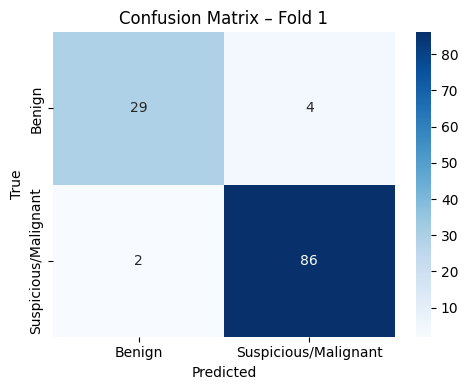

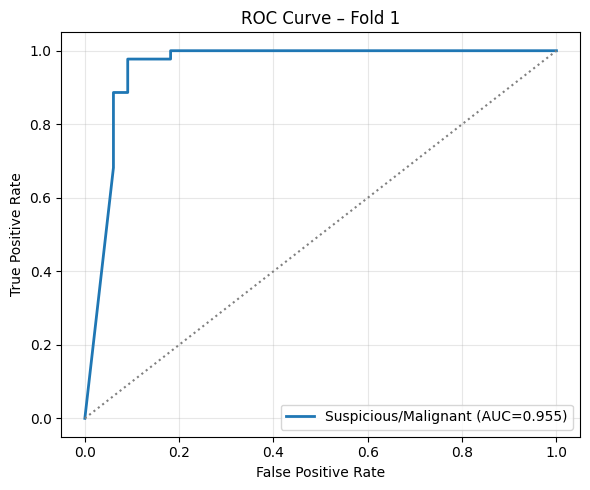


=== Fold 2 ===


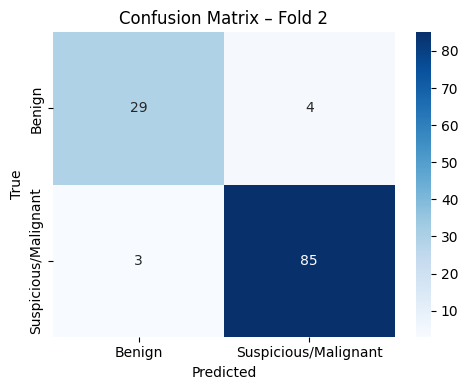

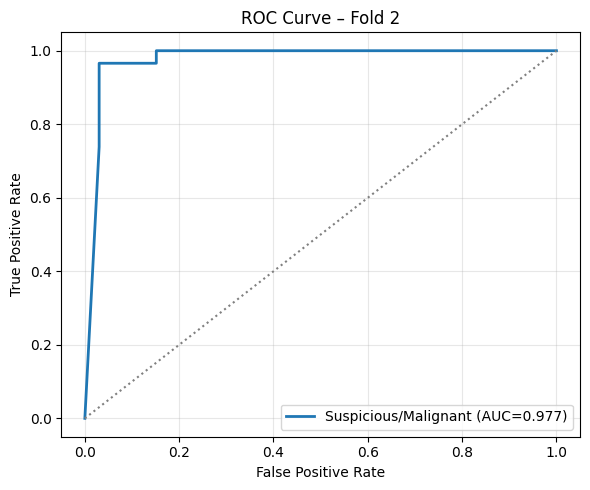


=== Fold 3 ===


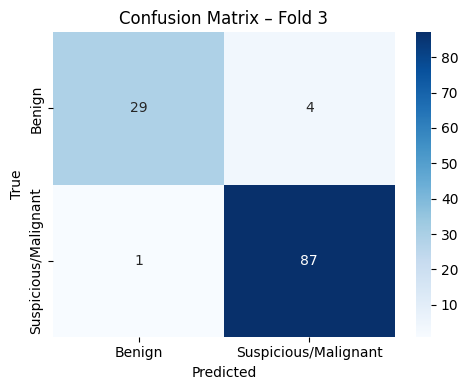

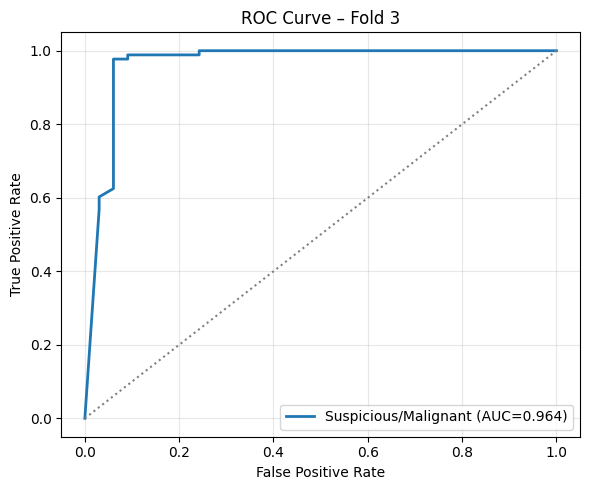


=== Fold 4 ===


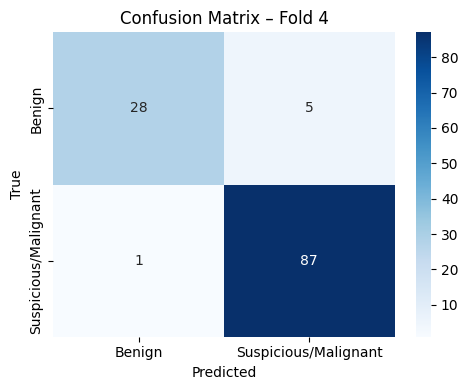

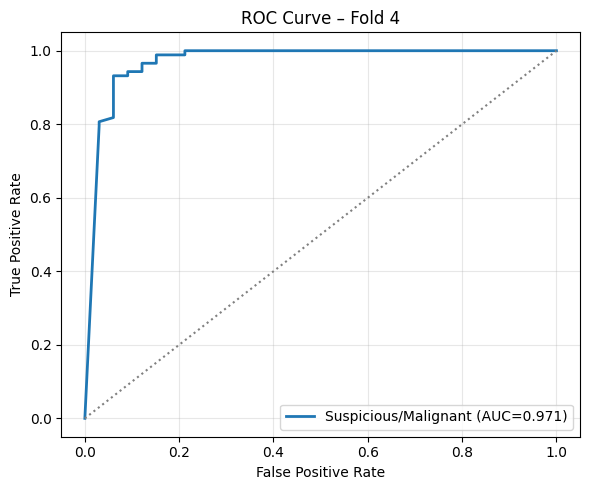


=== Fold 5 ===


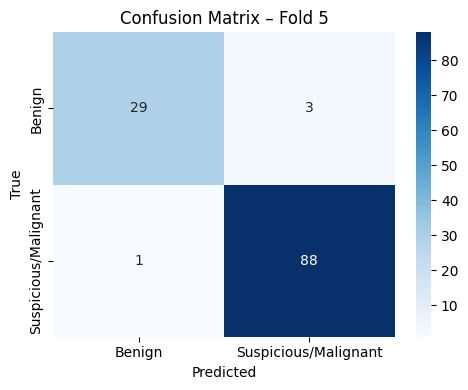

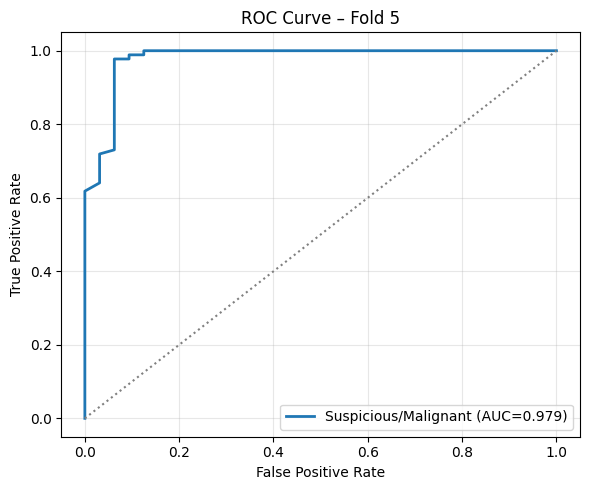


Mean Macro AUC: 0.9689607708855666


In [ ]:
all_conf_mats = []
macro_aucs = []

for fold_result in RESULTS:
    fold_idx = fold_result["fold"]

    # === UPDATED FIELD ACCESS ===
    cm = np.array(fold_result["confusion_matrix"])
    fpr = fold_result["fpr"]
    tpr = fold_result["tpr"]
    roc_auc = fold_result["roc_auc_dict"]

    cm_path = os.path.join(RESULTS_DIR, f"cm_fold{fold_idx+1}.png")
    roc_path = os.path.join(RESULTS_DIR, f"roc_fold{fold_idx+1}.png")

    print(f"\n=== Fold {fold_idx+1} ===")

    plot_cm(cm, title=f"Confusion Matrix – Fold {fold_idx+1}", savepath=cm_path)
    plot_roc(fpr, tpr, roc_auc, title=f"ROC Curve – Fold {fold_idx+1}",
             num_classes=NUM_CLASSES, savepath=roc_path)

    all_conf_mats.append(cm)
    macro_aucs.append(roc_auc["macro"])

print("\nMean Macro AUC:", np.mean(macro_aucs))

Save to Drive

In [ ]:
# Save the results DataFrame to Google Drive
results_filepath = os.path.join(RESULTS_DIR, "kfold_results_summary.csv")
df_results.to_csv(results_filepath, index=False)
print(f"Results summary saved to: {results_filepath}")

# The plotting and saving for individual folds and mean CM/ROC is already done in the previous cell.
# This cell can now focus on saving the results dataframe and confirming the plot locations.

# Inform the user where the plots are saved
print(f"Individual fold plots (CM and ROC) are saved in: {RESULTS_DIR}")
print(f"Mean Confusion Matrix is saved as: {os.path.join(RESULTS_DIR, 'cm_mean.png')}")
# Note: We are not calculating or plotting a single 'macro-average ROC across folds' curve here,
# but rather the individual fold ROCs and their mean AUC.

Results summary saved to: /content/drive/MyDrive/AIMLGroup18/Ekyaalo_Binary_Classifier/MobileNet_V3/kfold_results_summary.csv
Individual fold plots (CM and ROC) are saved in: /content/drive/MyDrive/AIMLGroup18/Ekyaalo_Binary_Classifier/MobileNet_V3
Mean Confusion Matrix is saved as: /content/drive/MyDrive/AIMLGroup18/Ekyaalo_Binary_Classifier/MobileNet_V3/cm_mean.png
